# ICT-15c — Méta-proxy d'obstruction : structure des désaccords entre proxys

**Issue** : [#7395](https://github.com/jsboige/CoursIA/issues/7395)
**Epic** : [#4588](https://github.com/jsboige/CoursIA/issues/4588) (IIT -> ICT)
**Jumeau C#** de [ICT-15c-MetaProxyObstruction-Python.ipynb](ICT-15c-MetaProxyObstruction-Python.ipynb) (issue [#27735](https://github.com/jsboige/CoursIA/issues/27735))

> **Ce que porte ce carnet.** Les mêmes quatre substrats, les mêmes trois proxys et le même verdict falsifiable que la source Python, mais calculés sur la bibliothèque standard .NET : pas de NumPy, pas de SciPy. Les six organes (`transition_matrix`, `transition_graph`, `laplacien` + valeurs propres, `observed_adjacency`, `local_sensitivity`, `obstruction_vector`) sont portés à la main, et deux d'entre eux sont remplacés par un équivalent déclaré : le RNG numpy (PCG64) devient un **xorshift64\*** déterministe par graine, et `np.linalg.eigvalsh` devient une **rotation de Jacobi** cyclique.

## Cadrage

L'intuition directrice (lecture cohomologie-obstruction, cf. doc Grothendieck
mergée le 19/07/2026) est que **l'obstruction elle-même est informative** :
quand plusieurs proxys de complexité/intégration (spectral, sensitivity,
free-energy) ne « recollent » pas en une mesure globale unique, le *motif*
de leur désaccord porte de l'information sur le substrat.

## Acceptance (issue #7395, falsifiable)

- **Positif** : motif de désaccord **stable cross-substrat** (montrer qu'il
  n'est pas arbitraire — même structure de désaccord sur ≥ 2 substrats).
- **Négatif honnête** : motif = bruit (pas de structure stable) → verdict
  négatif documenté, la jambe meurt proprement.
- **Premier livrable concret** : cas où la lecture-obstruction change une
  décision expérimentale ou une visualisation (pas un habillage rétrospectif).

## Discipline (HARD)

**Ne pas nommer l'objet** tant qu'il n'est pas stabilisé. Le nom
(grothendieckien, « structure » et non « mesure ») vient *après* la
stabilisation empirique, pas avant. Pas de lettre grecque décorée sur un
objet non encore constaté.

## Substrats pilotes (4 instrumentés)

1. **Gray-Scott** (réaction-diffusion, Turing patterns) — port de `ict.reaction_diffusion.GrayScott`
2. **Axelrod** (morphodynamique stratégique, fin de cycle réplicateur) — port de `ict.strategic_morphodynamics`
3. **Grokking** (compression crossover) — marche aléatoire biaisée sur alphabet à 4 états
4. **May** (pâturage bistable, ICT-8) — port de `ict.bistable.GrazingModel.simulate_sde`

## Livrable de cette notebook

Application du port C# de `ict.meta_proxy` sur 4 substrats synthétiques,
avec verdict falsifiable `STABLE / NOISE / INCONCLUSIVE` à la fin.

> **Statut épistémique** — **hypothèse** : Le **motif de désaccord** entre proxys est stable cross-substrat = obstruction informative (≠ dispersion d'échelle). Portée et détail dans la [matrice de dissociations](../../../../docs/ict/dissociations-matrix.md).

In [1]:
#r "nuget: ScottPlot, 5.0.55"
// Appareil du jumeau C# : RNG deterministe, substrats, six organes portes.
// Le RNG numpy (PCG64) n'est pas reproductible en .NET : on le remplace par un
// xorshift64* seede (meme choix que le jumeau ICT-15, #27734), lui aussi
// deterministe par graine. Gray-Scott et Axelrod rendent les memes signatures
// que la source (attracteur, dominance stable) ; Grokking et May rendent
// d'autres tirages, compares a tolerance de Monte-Carlo
// (cf. twin_pairs.d/ict-15c-metaproxyobstruction.yaml).
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using ScottPlot;
using Microsoft.DotNet.Interactive;

// ---------------------------------------------------------------------------
// RNG : xorshift64*
// ---------------------------------------------------------------------------
public sealed class Rng64
{
    private ulong _x;
    private double _spare;
    private bool _hasSpare;

    public Rng64(ulong seed)
    {
        _x = seed == 0UL ? 0x9E3779B97F4A7C15UL : seed;
    }

    public ulong NextUInt64()
    {
        ulong x = _x;
        x ^= x >> 12;
        x ^= x << 25;
        x ^= x >> 27;
        _x = x;
        return x * 0x2545F4914F6CDD1DUL;
    }

    public double NextDouble() => (NextUInt64() >> 11) * (1.0 / 9007199254740992.0);

    public int NextInt(int lo, int hi)
    {
        if (hi <= lo) return lo;
        return lo + (int)(NextDouble() * (hi - lo));
    }

    // Box-Muller avec reserve (equivalent de Generator.standard_normal)
    public double NextNormal()
    {
        if (_hasSpare) { _hasSpare = false; return _spare; }
        double u1, u2, s;
        do
        {
            u1 = 2.0 * NextDouble() - 1.0;
            u2 = 2.0 * NextDouble() - 1.0;
            s = u1 * u1 + u2 * u2;
        } while (s >= 1.0 || s == 0.0);
        double f = Math.Sqrt(-2.0 * Math.Log(s) / s);
        _spare = u2 * f;
        _hasSpare = true;
        return u1 * f;
    }
}

// ---------------------------------------------------------------------------
// Statistiques (conventions numpy : quantile 'linear', digitize a droite exclue,
// ecart-type de population ddof=0)
// ---------------------------------------------------------------------------
public static class Stats
{
    public static double[] Linspace(double a, double b, int n)
    {
        var r = new double[n];
        if (n <= 0) return r;
        if (n == 1) { r[0] = a; return r; }
        double step = (b - a) / (n - 1);
        for (int i = 0; i < n - 1; i++) r[i] = a + i * step;
        r[n - 1] = b;
        return r;
    }

    public static double[] Quantiles(IEnumerable<double> data, double[] qs)
    {
        var sorted = data.ToArray();
        Array.Sort(sorted);
        int n = sorted.Length;
        var res = new double[qs.Length];
        if (n == 0) return res;
        for (int k = 0; k < qs.Length; k++)
        {
            double pos = qs[k] * (n - 1);
            int lo = (int)Math.Floor(pos);
            if (lo < 0) lo = 0;
            if (lo > n - 1) lo = n - 1;
            int hi = Math.Min(lo + 1, n - 1);
            double frac = pos - lo;
            res[k] = sorted[lo] + frac * (sorted[hi] - sorted[lo]);
        }
        return res;
    }

    // np.digitize(x, bins) : index i tel que bins[i-1] <= x < bins[i]
    public static int[] Digitize(double[] x, double[] bins)
    {
        var r = new int[x.Length];
        for (int i = 0; i < x.Length; i++)
        {
            int idx = 0;
            while (idx < bins.Length && x[i] >= bins[idx]) idx++;
            r[i] = idx;
        }
        return r;
    }

    public static double[] Flatten(double[,] a)
    {
        int n = a.GetLength(0), m = a.GetLength(1);
        var r = new double[n * m];
        int k = 0;
        for (int i = 0; i < n; i++)
            for (int j = 0; j < m; j++) r[k++] = a[i, j];
        return r;
    }

    public static double Mean(IReadOnlyList<double> v)
    {
        if (v.Count == 0) return 0.0;
        double s = 0.0;
        for (int i = 0; i < v.Count; i++) s += v[i];
        return s / v.Count;
    }

    public static double StdPop(IReadOnlyList<double> v)
    {
        if (v.Count == 0) return 0.0;
        double m = Mean(v);
        double s = 0.0;
        for (int i = 0; i < v.Count; i++) { double d = v[i] - m; s += d * d; }
        return Math.Sqrt(s / v.Count);
    }

    public static double Percentile(double[] v, double p)
        => v.Length == 0 ? 0.0 : Quantiles(v, new[] { p })[0];

    public static double Max(IReadOnlyList<double> v)
    {
        if (v.Count == 0) return 0.0;
        double m = v[0];
        for (int i = 1; i < v.Count; i++) if (v[i] > m) m = v[i];
        return m;
    }

    public static double Min(IReadOnlyList<double> v)
    {
        if (v.Count == 0) return 0.0;
        double m = v[0];
        for (int i = 1; i < v.Count; i++) if (v[i] < m) m = v[i];
        return m;
    }
}

// ---------------------------------------------------------------------------
// Substrat 1 : Gray-Scott (port de ict.reaction_diffusion)
// ---------------------------------------------------------------------------
public sealed class GrayScott
{
    public double F { get; }
    public double Kill { get; }
    public double Du { get; }
    public double Dv { get; }
    public double Dt { get; }

    public GrayScott(double feed = 0.0367, double kill = 0.0649, double du = 0.16, double dv = 0.08, double step = 1.0)
    {
        F = feed; Kill = kill; Du = du; Dv = dv; Dt = step;
    }

    // Stencil 5 points a bords periodiques. L'ordre d'association reproduit
    // celui de ict.reaction_diffusion.laplacian :
    //   roll(+1, axe0) + roll(-1, axe0) + roll(+1, axe1) + roll(-1, axe1) - 4*f
    public static double[,] Laplacian(double[,] field)
    {
        int n = field.GetLength(0), m = field.GetLength(1);
        var r = new double[n, m];
        for (int i = 0; i < n; i++)
        {
            int im = (i - 1 + n) % n;
            int ip = (i + 1) % n;
            for (int j = 0; j < m; j++)
            {
                int jm = (j - 1 + m) % m;
                int jp = (j + 1) % m;
                r[i, j] = field[im, j] + field[ip, j] + field[i, jm] + field[i, jp] - 4.0 * field[i, j];
            }
        }
        return r;
    }

    public (double[,] U, double[,] V) Seed(int n = 96, int block = 12, double noise = 0.02, Rng64 rng = null)
    {
        var U = new double[n, n];
        var V = new double[n, n];
        for (int i = 0; i < n; i++)
            for (int j = 0; j < n; j++) U[i, j] = 1.0;
        int lo = n / 2 - block / 2;
        int hi = lo + block;
        for (int i = lo; i < hi; i++)
            for (int j = lo; j < hi; j++) { U[i, j] = 0.50; V[i, j] = 0.25; }
        if (noise > 0.0)
        {
            var g = rng ?? new Rng64(0UL);
            for (int i = 0; i < n; i++)
                for (int j = 0; j < n; j++)
                {
                    U[i, j] += noise * g.NextNormal();
                    V[i, j] += noise * g.NextNormal();
                }
        }
        for (int i = 0; i < n; i++)
            for (int j = 0; j < n; j++)
            {
                U[i, j] = Math.Clamp(U[i, j], 0.0, 1.0);
                V[i, j] = Math.Clamp(V[i, j], 0.0, 1.0);
            }
        return (U, V);
    }

    public (double[,] U, double[,] V) Step(double[,] U, double[,] V)
    {
        var lapU = Laplacian(U);
        var lapV = Laplacian(V);
        int n = U.GetLength(0), m = U.GetLength(1);
        var Un = new double[n, m];
        var Vn = new double[n, m];
        for (int i = 0; i < n; i++)
            for (int j = 0; j < m; j++)
            {
                double reaction = U[i, j] * V[i, j] * V[i, j];
                Un[i, j] = Math.Clamp(U[i, j] + Dt * (Du * lapU[i, j] - reaction + F * (1.0 - U[i, j])), 0.0, 1.0);
                Vn[i, j] = Math.Clamp(V[i, j] + Dt * (Dv * lapV[i, j] + reaction - (F + Kill) * V[i, j]), 0.0, 1.0);
            }
        return (Un, Vn);
    }

    public (double[,] U, double[,] V) Run(double[,] U, double[,] V, int steps)
    {
        for (int t = 0; t < steps; t++)
        {
            var s = Step(U, V);
            U = s.U; V = s.V;
        }
        return (U, V);
    }
}

// ---------------------------------------------------------------------------
// Substrat 2 : Axelrod (port de ict.strategic_morphodynamics)
// ---------------------------------------------------------------------------
public delegate int StrategyFn(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng);

public static class Ipd
{
    public const int C = 0;
    public const int D = 1;
    public static readonly double T = 5.0;
    public static readonly double R = 3.0;
    public static readonly double P = 1.0;
    public static readonly double S = 0.0;

    public static (double a, double b) PayoffPair(int a, int b)
    {
        if (a == C && b == C) return (R, R);
        if (a == C && b == D) return (S, T);
        if (a == D && b == C) return (T, S);
        return (P, P);
    }

    public static int AllC(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng) => C;
    public static int AllD(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng) => D;

    public static int Tft(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng)
        => opp.Count == 0 ? C : opp[opp.Count - 1];

    // Seule strategie consommatrice du RNG (protocole etendu #13322).
    public static int GTft(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng)
    {
        if (opp.Count == 0) return C;
        if (opp[opp.Count - 1] == C) return C;
        return rng.NextDouble() < 1.0 / 3.0 ? C : D;
    }

    public static int Pavlov(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng)
    {
        if (own.Count == 0) return C;
        int last = own[own.Count - 1];
        int oppLast = opp[opp.Count - 1];
        var (pa, _) = PayoffPair(last, oppLast);
        bool won = pa >= R;
        return won ? last : 1 - last;
    }

    public static int Grim(IReadOnlyList<int> own, IReadOnlyList<int> opp, Rng64 rng)
    {
        for (int i = 0; i < opp.Count; i++) if (opp[i] == D) return D;
        return C;
    }

    // Ordre d'insertion identique au dict Python (dict preserve l'ordre).
    public static List<KeyValuePair<string, StrategyFn>> MakeStrategies()
    {
        var l = new List<KeyValuePair<string, StrategyFn>>();
        l.Add(new KeyValuePair<string, StrategyFn>("allc", AllC));
        l.Add(new KeyValuePair<string, StrategyFn>("alld", AllD));
        l.Add(new KeyValuePair<string, StrategyFn>("tft", Tft));
        l.Add(new KeyValuePair<string, StrategyFn>("gtft", GTft));
        l.Add(new KeyValuePair<string, StrategyFn>("pavlov", Pavlov));
        l.Add(new KeyValuePair<string, StrategyFn>("grim", Grim));
        return l;
    }

    public static (double g1, double g2) PlayMatch(StrategyFn s1, StrategyFn s2, int nRounds, double noise, Rng64 rng)
    {
        var own1 = new List<int>();
        var own2 = new List<int>();
        double g1 = 0.0, g2 = 0.0;
        for (int t = 0; t < nRounds; t++)
        {
            int a = s1(own1, own2, rng);
            int b = s2(own2, own1, rng);
            if (noise > 0.0)
            {
                if (rng.NextDouble() < noise) a = 1 - a;
                if (rng.NextDouble() < noise) b = 1 - b;
            }
            var (pa, pb) = PayoffPair(a, b);
            g1 += pa; g2 += pb;
            own1.Add(a); own2.Add(b);
        }
        return (g1 / nRounds, g2 / nRounds);
    }

    public static double[,] PayoffMatrix(List<KeyValuePair<string, StrategyFn>> strategies,
                                         int nRounds, int nReps, Rng64 rng)
    {
        int n = strategies.Count;
        var A = new double[n, n];
        for (int i = 0; i < n; i++)
            for (int j = 0; j < n; j++)
            {
                double sum = 0.0;
                for (int r = 0; r < nReps; r++)
                {
                    var (gi, _) = PlayMatch(strategies[i].Value, strategies[j].Value, nRounds, 0.0, rng);
                    sum += gi;
                }
                A[i, j] = sum / nReps;
            }
        return A;
    }

    public static double[,] ReplicatorTrajectory(double[,] A, double[] x0, int nSteps)
    {
        int n = x0.Length;
        var x = (double[])x0.Clone();
        double total = 0.0;
        for (int i = 0; i < n; i++) total += x[i];
        for (int i = 0; i < n; i++) x[i] /= total;
        var traj = new double[nSteps + 1, n];
        for (int i = 0; i < n; i++) traj[0, i] = x[i];
        for (int t = 0; t < nSteps; t++)
        {
            var f = new double[n];
            for (int i = 0; i < n; i++)
            {
                double s = 0.0;
                for (int j = 0; j < n; j++) s += A[i, j] * x[j];
                f[i] = s;
            }
            double avg = 0.0;
            for (int i = 0; i < n; i++) avg += f[i] * x[i];
            if (avg < 1e-12) break;
            double tot = 0.0;
            for (int i = 0; i < n; i++)
            {
                x[i] = Math.Max(0.0, x[i] * f[i] / avg);
                tot += x[i];
            }
            if (tot > 1e-12)
                for (int i = 0; i < n; i++) x[i] /= tot;
            for (int i = 0; i < n; i++) traj[t + 1, i] = x[i];
        }
        return traj;
    }
}

// ---------------------------------------------------------------------------
// Substrat 4 : May (port de ict.bistable.GrazingModel.simulate_sde)
// ---------------------------------------------------------------------------
public sealed class Grazing
{
    public double R { get; }
    public double K { get; }
    public double H { get; }

    public Grazing(double r = 1.0, double k = 10.0, double h = 1.0) { R = r; K = k; H = h; }

    public double Rate(double x, double c)
        => R * x * (1.0 - x / K) - c * x * x / (x * x + H * H);

    public double[] SimulateSde(double c, double x0, double sigma, double dt, int T, ulong seed)
    {
        var g = new Rng64(seed);
        double sq = Math.Sqrt(dt);
        double x = x0;
        var xs = new double[T];
        for (int t = 0; t < T; t++)
        {
            x = x + dt * Rate(x, c) + sigma * sq * g.NextNormal();
            if (x < 0.0) x = 0.0;
            xs[t] = x;
        }
        return xs;
    }
}

// ---------------------------------------------------------------------------
// Organe spectral (port de ict.spectral : matrice de transition, graphe
// symetrique sans boucle, Laplacien, gap)
// ---------------------------------------------------------------------------
public static class Spectral
{
    // P[s, t] += 1 seulement si les deux indices sont dans [0, n) ; les paires
    // hors bornes sont silencieusement ignorees (convention de la source).
    public static double[,] TransitionMatrix(IReadOnlyList<int> states, int nSymbols, double eps = 1e-9)
    {
        var P = new double[nSymbols, nSymbols];
        for (int i = 0; i < nSymbols; i++)
            for (int j = 0; j < nSymbols; j++) P[i, j] = eps;
        for (int t = 0; t + 1 < states.Count; t++)
        {
            int s = states[t], u = states[t + 1];
            if (s >= 0 && s < nSymbols && u >= 0 && u < nSymbols) P[s, u] += 1.0;
        }
        for (int i = 0; i < nSymbols; i++)
        {
            double sum = 0.0;
            for (int j = 0; j < nSymbols; j++) sum += P[i, j];
            if (sum > 0.0)
                for (int j = 0; j < nSymbols; j++) P[i, j] /= sum;
        }
        return P;
    }

    public static double[,] TransitionGraph(IReadOnlyList<int> states, int nSymbols)
    {
        var P = TransitionMatrix(states, nSymbols);
        var W = new double[nSymbols, nSymbols];
        for (int i = 0; i < nSymbols; i++)
            for (int j = 0; j < nSymbols; j++) W[i, j] = (P[i, j] + P[j, i]) / 2.0;
        for (int i = 0; i < nSymbols; i++) W[i, i] = 0.0;
        return W;
    }

    // Valeurs propres par Jacobi cyclique (matrice symetrique reelle).
    public static double[] SymmetricEigenvalues(double[,] A, int maxSweeps = 100)
    {
        int n = A.GetLength(0);
        var a = (double[,])A.Clone();
        for (int sweep = 0; sweep < maxSweeps; sweep++)
        {
            double off = 0.0;
            for (int i = 0; i < n; i++)
                for (int j = i + 1; j < n; j++) off += a[i, j] * a[i, j];
            if (off < 1e-30) break;
            for (int p = 0; p < n - 1; p++)
                for (int q = p + 1; q < n; q++)
                {
                    if (Math.Abs(a[p, q]) < 1e-18) continue;
                    double theta = (a[q, q] - a[p, p]) / (2.0 * a[p, q]);
                    double t = theta == 0.0
                        ? 1.0
                        : Math.Sign(theta) / (Math.Abs(theta) + Math.Sqrt(theta * theta + 1.0));
                    double c = 1.0 / Math.Sqrt(t * t + 1.0);
                    double s = t * c;
                    for (int k = 0; k < n; k++)
                    {
                        double akp = a[k, p], akq = a[k, q];
                        a[k, p] = c * akp - s * akq;
                        a[k, q] = s * akp + c * akq;
                    }
                    for (int k = 0; k < n; k++)
                    {
                        double apk = a[p, k], aqk = a[q, k];
                        a[p, k] = c * apk - s * aqk;
                        a[q, k] = s * apk + c * aqk;
                    }
                }
        }
        var eigs = new double[n];
        for (int i = 0; i < n; i++) eigs[i] = a[i, i];
        Array.Sort(eigs);
        return eigs;
    }

    public static double[] LaplacianSpectrum(double[,] W)
    {
        int n = W.GetLength(0);
        var L = new double[n, n];
        for (int i = 0; i < n; i++)
        {
            double d = 0.0;
            for (int j = 0; j < n; j++) d += W[i, j];
            for (int j = 0; j < n; j++) L[i, j] = -W[i, j];
            L[i, i] = d; // D - W, et W_ii = 0
        }
        return SymmetricEigenvalues(L);
    }

    public static double SpectralGap(double[,] W)
    {
        var eigs = LaplacianSpectrum(W);
        if (eigs.Length < 2) return double.NaN;
        return eigs[1] - eigs[0];
    }

    public static double SpectralGapOf(IReadOnlyList<int> states, int nSymbols)
        => SpectralGap(TransitionGraph(states, nSymbols));
}

// ---------------------------------------------------------------------------
// Organe de sensibilite (port de ict.sensitivity, correctif #9764 : voisinage
// lu sur les transitions OBSERVEES, pas sur le graphe lisse)
// ---------------------------------------------------------------------------
public sealed class SensitivitySummary
{
    public double max;
    public double mean;
    public double std;
    public double p95;
    public int n_visited;
}

public static class Sensitivity
{
    // Ids compacts par ordre de PREMIERE APPARITION ; leve si un nouveau label
    // apparait alors que n_symbols est deja atteint.
    public static int[] EncodeLabels(IReadOnlyList<int> states, int nSymbols)
    {
        var map = new Dictionary<int, int>();
        var ids = new int[states.Count];
        for (int i = 0; i < states.Count; i++)
        {
            int lab = states[i];
            if (!map.TryGetValue(lab, out int id))
            {
                if (map.Count >= nSymbols)
                    throw new InvalidOperationException(
                        $"trop de labels distincts pour n_symbols={nSymbols}");
                id = map.Count;
                map[lab] = id;
            }
            ids[i] = id;
        }
        return ids;
    }

    // Adjacence OBSERVEE : booleenne, symetrique, boucles exclues, paires hors
    // bornes ignorees, aucun lissage.
    public static bool[,] ObservedAdjacency(IReadOnlyList<int> states, int nSymbols)
    {
        var A = new bool[nSymbols, nSymbols];
        for (int t = 0; t + 1 < states.Count; t++)
        {
            int s = states[t], u = states[t + 1];
            if (s == u) continue;
            if (s < 0 || s >= nSymbols || u < 0 || u >= nSymbols) continue;
            A[s, u] = true;
            A[u, s] = true;
        }
        return A;
    }

    public static int[] Local(IReadOnlyList<int> states, int nSymbols, Func<int, int> f)
    {
        var ids = EncodeLabels(states, nSymbols);
        var A = ObservedAdjacency(ids, nSymbols);
        var fVals = new int[nSymbols];
        for (int i = 0; i < nSymbols; i++) fVals[i] = f(i);
        var s = new int[nSymbols];
        for (int x = 0; x < nSymbols; x++)
        {
            int count = 0;
            for (int y = 0; y < nSymbols; y++)
                if (A[x, y] && fVals[y] != fVals[x]) count++;
            s[x] = count;
        }
        return s;
    }

    // Les noeuds visites occupent les ids 0..n_visited-1 (encodage compact par
    // premiere apparition) : le prefixe suffit.
    public static SensitivitySummary Distribution(IReadOnlyList<int> states, int nSymbols, Func<int, int> f)
    {
        var s = Local(states, nSymbols, f);
        var distinct = new HashSet<int>(states);
        int nVisited = distinct.Count;
        var visited = new List<double>();
        for (int i = 0; i < Math.Min(nVisited, s.Length); i++) visited.Add(s[i]);
        return new SensitivitySummary
        {
            max = visited.Count == 0 ? 0.0 : Stats.Max(visited),
            mean = visited.Count == 0 ? 0.0 : Stats.Mean(visited),
            std = visited.Count == 0 ? 0.0 : Stats.StdPop(visited),
            p95 = visited.Count == 0 ? 0.0 : Stats.Percentile(visited.ToArray(), 95),
            n_visited = nVisited
        };
    }
}

// ---------------------------------------------------------------------------
// Meta-proxy (port de ict.meta_proxy : signature, vecteur d'obstruction,
// aggregation cross-substrat)
// ---------------------------------------------------------------------------
public sealed class Signature
{
    public int n_states;
    public int n_transitions;
    public double spectral_gap;
    public double sensitivity_mean;
    public double sensitivity_max;

    public double this[string key]
    {
        get
        {
            switch (key)
            {
                case "spectral_gap": return spectral_gap;
                case "sensitivity_mean": return sensitivity_mean;
                case "sensitivity_max": return sensitivity_max;
                case "n_states": return n_states;
                case "n_transitions": return n_transitions;
                default: return 0.0;
            }
        }
    }
}

public sealed class VerdictResult
{
    public int n_substrats;
    public List<double> pairwise_norms;
    public double mean_norm_l2;
    public double max_norm_l2;
    public double stable_threshold;
    public double noise_threshold;
    public string verdict;
}

public static class MetaProxy
{
    public static readonly string[] DefaultKeys = { "spectral_gap", "sensitivity_mean", "sensitivity_max" };

    public static Signature SignatureFrom(IReadOnlyList<int> states, int nSymbols,
                                          Func<IReadOnlyList<int>, int, double> spectralFn,
                                          Func<IReadOnlyList<int>, int, double> meanFn,
                                          Func<IReadOnlyList<int>, int, double> maxFn)
    {
        if (nSymbols < 2) throw new ArgumentException("n_symbols doit etre >= 2");
        if (states.Count == 0) throw new ArgumentException("states vide");
        if (states.Count < 2) throw new ArgumentException("states doit contenir >= 2 pas");
        return new Signature
        {
            n_states = states.Count,
            n_transitions = states.Count - 1,
            spectral_gap = spectralFn(states, nSymbols),
            sensitivity_mean = meanFn(states, nSymbols),
            sensitivity_max = maxFn(states, nSymbols)
        };
    }

    public static Signature Signature(IReadOnlyList<int> states, int nSymbols)
        => SignatureFrom(states, nSymbols,
                         (st, n) => Spectral.SpectralGapOf(st, n),
                         (st, n) => Sensitivity.Distribution(st, n, x => x).mean,
                         (st, n) => Sensitivity.Distribution(st, n, x => x).max);

    public static (double spectral, double sensMean, double sensMax, double normL2)
        ObstructionVector(Signature a, Signature b, string[] keys = null)
    {
        keys = keys ?? DefaultKeys;
        const double eps = 1e-12;
        double sg = 0.0, sm = 0.0, sx = 0.0;
        double sumSq = 0.0;
        foreach (var k in keys)
        {
            double va = a[k], vb = b[k];
            if (double.IsNaN(va) || double.IsInfinity(va)) va = 0.0;
            if (double.IsNaN(vb) || double.IsInfinity(vb)) vb = 0.0;
            double d = (va - vb) / (Math.Abs(va) + Math.Abs(vb) + eps);
            sumSq += d * d;
            if (k == "spectral_gap") sg = d;
            else if (k == "sensitivity_mean") sm = d;
            else if (k == "sensitivity_max") sx = d;
        }
        return (sg, sm, sx, Math.Sqrt(sumSq));
    }

    public static VerdictResult CrossSubstratObstruction(
        IReadOnlyList<KeyValuePair<string, Signature>> sigs,
        double stableThreshold = 0.05, double noiseThreshold = 0.30)
    {
        if (sigs.Count < 2) throw new ArgumentException("cross_substrat_obstruction necessite >= 2 substrats");
        var norms = new List<double>();
        for (int i = 0; i < sigs.Count; i++)
            for (int j = i + 1; j < sigs.Count; j++)
                norms.Add(ObstructionVector(sigs[i].Value, sigs[j].Value).normL2);
        double mean = Stats.Mean(norms);
        double max = Stats.Max(norms);
        string verdict = mean <= stableThreshold ? "STABLE"
                       : (mean >= noiseThreshold ? "NOISE" : "INCONCLUSIVE");
        return new VerdictResult
        {
            n_substrats = sigs.Count,
            pairwise_norms = norms,
            mean_norm_l2 = mean,
            max_norm_l2 = max,
            stable_threshold = stableThreshold,
            noise_threshold = noiseThreshold,
            verdict = verdict
        };
    }
}

// ---------------------------------------------------------------------------
// Deux couleurs de texte pour la figure
// ---------------------------------------------------------------------------
public static class Palette
{
    public static readonly ScottPlot.Color Blanc = new ScottPlot.Color(255, 255, 255);
    public static readonly ScottPlot.Color Noir = new ScottPlot.Color(0, 0, 0);
}

// ---------------------------------------------------------------------------
// Culture (c.94 : les TROIS setters, sinon separateur decimal virgule)
// ---------------------------------------------------------------------------
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;

Console.WriteLine("meta_proxy porte en C#. Substrats pilotes : Gray-Scott, Axelrod, Grokking, May (ICT-8).");

Installed Packages ScottPlot, 5.0.55

meta_proxy porte en C#. Substrats pilotes : Gray-Scott, Axelrod, Grokking, May (ICT-8).


In [2]:
// --- Substrat 1 : Gray-Scott Turing patterns ---
// Deux essais, comme la source Python. Le premier (quantiles de U) est
// disqualifie par sa propre sortie : U est constant a 4 decimales, et ses
// quantiles ne decoupent que le residu numerique de la convergence. Le second
// (binarisation de V) est retenu.
var gs = new GrayScott(0.035, 0.065, 0.16, 0.08, 1.0);
var seedRng = new Rng64(20260720UL);
var initField = gs.Seed(64, 12, 0.02, seedRng);
var run1 = gs.Run(initField.U, initField.V, 800);
var uFinal = run1.U;
var vFinal = run1.V;

// Essai 1 : discretisation de U en 4 quantiles.
var uFlat = Stats.Flatten(uFinal);
var uQ = Stats.Quantiles(uFlat, new[] { 0.25, 0.50, 0.75 });
var gsStatesEssai1 = Stats.Digitize(uFlat, uQ);
int uniqGsEssai1 = new HashSet<int>(gsStatesEssai1).Count;
int nSymbolsGsEssai1 = 4;
var effectifsEssai1 = new int[nSymbolsGsEssai1];
foreach (var s in gsStatesEssai1) effectifsEssai1[s]++;
Console.WriteLine($"Gray-Scott (essai 1, quantiles de U) : U range=[{Stats.Min(uFlat):F4}, {Stats.Max(uFlat):F4}], "
                + $"amplitude={Stats.Max(uFlat) - Stats.Min(uFlat):E2}, "
                + $"n_symbols={nSymbolsGsEssai1}, len(states)={gsStatesEssai1.Length}, unique={uniqGsEssai1}, "
                + $"effectifs=[{string.Join(", ", effectifsEssai1)}]");

// Essai 2 (retenu) : binarisation V > 0.5 -> 1 (pattern), sinon 0 (fond).
var vFlat = Stats.Flatten(vFinal);
var binaryGrid = new int[vFlat.Length];
int nPattern = 0;
for (int i = 0; i < vFlat.Length; i++)
{
    binaryGrid[i] = vFlat[i] > 0.5 ? 1 : 0;
    if (binaryGrid[i] == 1) nPattern++;
}
int nBg = binaryGrid.Length - nPattern;
double ratio = (double)nPattern / (nPattern + nBg);
Console.WriteLine($"Gray-Scott : pattern={nPattern}, background={nBg}, ratio={ratio:F3}, "
                + $"V max={Stats.Max(vFlat):E2}");

var gray_scott_states = binaryGrid;
int n_symbols_gs = 2;
Console.WriteLine($"Longueur trajectoire Gray-Scott : {gray_scott_states.Length} pixels");

Gray-Scott (essai 1, quantiles de U) : U range=[1.0000, 1.0000], amplitude=3.62E-012, n_symbols=4, len(states)=4096, unique=4, effectifs=[1024, 1024, 1023, 1025]


Gray-Scott : pattern=0, background=4096, ratio=0.000, V max=9.24E-032


Longueur trajectoire Gray-Scott : 4096 pixels


## Lecture 1 -- Gray-Scott par défaut : le substrat plat comme contrôle

La cellule ci-dessus contient deux essais. Le premier (quantiles de U) est disqualifié par sa propre sortie : `U range=[1.0000, 1.0000]` — le champ U est constant à 4 décimales après 800 pas, il ne reste qu'un résidu numérique d'amplitude `3.6e-12`. Ce résidu suffit aux trois quantiles internes pour découper `4` classes équiprobables (c'est la définition d'un quantile) : les `4096` symboles de la « trajectoire » de l'essai 1 ne portent que le bruit d'arrondi de la convergence, aucun motif de Turing. Le second (binarisation de V) est plus honnête : `pattern=0, background=4096, ratio=0.000` — aucun pixel ne dépasse V > 0.5 (V max = `9.2e-32`), la grille 64×64 reste uniforme : V s'effondre vers 0 avec ces paramètres dans la fenêtre de 800 pas (F = 0.035 / k = 0.065).

Conséquence pour la suite : la signature Gray-Scott (`spectral_gap = 0.5000`, sensibilité `0.0000/0.0000`) est celle d'une séquence constante, pas d'un motif de Turing. Le banc le garde néanmoins — comme **contrôle trivial** : un substrat dont l'observable ne varie pas fixe l'extrémité basse de l'échelle des proxys, et tout vecteur d'obstruction qui l'implique doit être lu avec cette réserve. C'est aussi un rappel expérimental : la fenêtre d'intégration et les paramètres (F, k) font partie du substrat testé.

L'essai retenu et la signature de ce substrat sont **identiques à la source Python** : l'attracteur `(U=1, V=0)` absorbe le bruit initial, et le RNG différent ne déplace que le résidu numérique. C'est un point d'ancrage de la parité.

In [3]:
// --- Substrat 2 : Axelrod end-of-cycle replicator ---
var rng = new Rng64(20260720UL);
var strategies = Ipd.MakeStrategies();
var A = Ipd.PayoffMatrix(strategies, 200, 3, rng);
int nStrat = A.GetLength(0);
var x0 = new double[nStrat];
for (int i = 0; i < nStrat; i++) x0[i] = 1.0 / nStrat;
var traj = Ipd.ReplicatorTrajectory(A, x0, 400);

// Essai 1 : index brut de la strategie dominante a chaque pas.
var domIdx = new int[traj.GetLength(0)];
for (int t = 0; t < traj.GetLength(0); t++)
{
    int best = 0;
    for (int i = 1; i < nStrat; i++) if (traj[t, i] > traj[t, best]) best = i;
    domIdx[t] = best;
}
var axelrodStatesEssai1 = domIdx;
int nSymbolsAxEssai1 = nStrat;
Console.WriteLine($"Axelrod (essai 1, index dominant brut) : trajectoire de {axelrodStatesEssai1.Length} pas, "
                + $"alphabet={nSymbolsAxEssai1}.");

// Essai 2 (retenu) : binarisation de la stabilite de la dominance.
var axelrod_states = new int[domIdx.Length - 1];
for (int i = 1; i < domIdx.Length; i++) axelrod_states[i - 1] = domIdx[i] == domIdx[i - 1] ? 1 : 0;
int n_symbols_ax = 2;
Console.WriteLine($"Axelrod : trajectoire de {axelrod_states.Length} pas (stabilite de la dominance).");

Axelrod (essai 1, index dominant brut) : trajectoire de 401 pas, alphabet=6.


Axelrod : trajectoire de 400 pas (stabilite de la dominance).


In [4]:
// --- Substrat 3 : Grokking compression crossover (proxy minimal) ---
// Marche aleatoire biaisee : phase 1 = haute entropie (alphabet 4 etats),
// phase 2 = compression vers l'etat 0. Crossover au pas 200.
int nStepsG = 400;
var statesG = new int[nStepsG];
for (int t = 0; t < nStepsG; t++)
{
    if (t < 200)
    {
        statesG[t] = rng.NextInt(0, 4);
    }
    else
    {
        statesG[t] = rng.NextDouble() < 0.90 ? 0 : rng.NextInt(1, 4);
    }
}
var grokking_states = statesG;
int n_symbols_gk = 4;
Console.WriteLine($"Grokking : trajectoire de {grokking_states.Length} pas, crossover au pas 200.");

Grokking : trajectoire de 400 pas, crossover au pas 200.


In [5]:
// --- Substrat 4 : May (ICT-8, modele de paturage bistable) ---
// dx/dt = r*x*(1 - x/K) - c*x^2/(x^2 + h^2), Euler-Maruyama, bruit additif.
var gm = new Grazing(1.0, 10.0, 1.0);
var xsMay = gm.SimulateSde(1.5, 8.0, 0.05, 0.01, 2000, 20260720UL);
var mayQ = Stats.Quantiles(xsMay, Stats.Linspace(0.0, 1.0, 17).Skip(1).Take(15).ToArray());
var may_states = Stats.Digitize(xsMay, mayQ);
int n_symbols_may = 16;
Console.WriteLine($"May : x range=[{Stats.Min(xsMay):F4}, {Stats.Max(xsMay):F4}], "
                + $"n_symbols={n_symbols_may}, len(states)={may_states.Length}");

May : x range=[7.9983, 8.2491], n_symbols=16, len(states)=2000


## Lecture 2 -- Le banc des quatre régimes, lu à partir des trajectoires

Avant les proxys, lire les trajectoires. La cellule Axelrod fait deux essais ; la version retenue (dernière affectation, celle que les signatures utilisent) est la **stabilité de la dominance** : 400 pas, alphabet binaire stable/bascule. May (SDE de pâturage bistable, c = 1.5) reste dans un canal étroit : `x range=[7.9983, 8.2491]` sur 2000 pas — amplitude 0.2508 — tout en discrétisant 16 quantiles : la biomasse fluctue autour d'un seul attracteur, elle ne traverse pas le pli dans cette fenêtre. Grokking est une marche biaisée de 400 pas avec crossover au pas 200 : phase 1 haute entropie (équiprobable sur 4 états), phase 2 compression (90 % sur l'état 0). Gray-Scott est plat (Lecture 1).

Le contraste est volontaire (cellule « Le banc de quatre substrats ») : un canal quasi-constant, une alternance binaire, une transition de phase, une constante. Si un motif de désaccord entre proxys se retrouve transversalement à ces quatre régimes — de l'alphabet à 2 symboles au 16-quantiles, du spatial au temporel —, il ne peut pas être un artefact de domaine : c'est précisément la question falsifiable du méta-proxy.

**Ce que le RNG change.** Axelrod, Grokking et May sont stochastiques : leurs valeurs C# sont **mesurées ici**, pas recopiées de la source. Grokking et May s'en écartent (autres tirages) ; Axelrod retombe sur les mêmes proxys (`1.0000` partout), la dominance y étant stable sur toute la trajectoire dans les deux RNG. Les bornes de May valent ici `[7.9983, 8.2491]` contre `[7.9923, 8.3613]` en Python — un écart d'échantillonnage, pas un écart de modèle, déclaré dans `known_differences` de la paire.

### Le banc de quatre substrats : diversifier les régimes pour tester la cohérence

Les quatre substrats ci-dessus ne sont pas quatre instances d'une même
dynamique : ce sont **quatre régimes hétérogènes**, chacun converti en une
trajectoire discrète sur un alphabet propre.

| Substrat | Régime | Origine de la trajectoire | Alphabet |
|----------|--------|---------------------------|----------|
| **Gray-Scott** | motif spatial émergent | réaction-diffusion 2D, motif de Turing binarisé | 2 (pattern / fond) |
| **Axelrod** | dynamique stratégique | replicateur end-of-cycle, stabilité du dominant | 2 (stable / bascule) |
| **Grokking** | transition de phase | marche biaisée, crossover haute-entropie vers compression | 4 |
| **May (ICT-8)** | pâturage bistable | SDE bistable, biomasse quantifiée | 16 |

Cette diversité est **volontaire** : c'est le banc de test du méta-proxy. Si la
structure des désaccords entre proxys se révèle **cohérente** d'un régime à
l'autre — de la maille binaire au 16-quantiles, du motif spatial à la
transition d'apprentissage — c'est la signature d'un **invariant portable** :
l'obstruction mesure une propriété réelle du substrat, pas un artefact de tel
ou tel domaine. À l'inverse, si chaque régime produit ses propres désaccords
idiosyncratiques, le méta-proxy n'est pas robuste. C'est la question
falsifiable que tranche le verdict ci-dessous.

L'étape suivante projette chaque substrat sur une **signature à trois proxys** :
le *spectral gap* (structure globale du graphe de transition) et la
*sensibilité* moyenne et maximale (réponse locale à la perturbation d'un
symbole).

In [6]:
// --- Calcul des signatures multi-proxys ---
// On enrobe les organes spectral / sensitivity pour matcher le prototype
// (states, n_symbols) -> double attendu par le meta-proxy.
Func<IReadOnlyList<int>, int, double> SpecGapWrap = (st, nSym) => Spectral.SpectralGapOf(st, nSym);

// f(x) = x : identite sur le vocabulaire (l'observable derivee du substrat est
// portee par le label ordinal du noeud, pas par une fonction-test). C'est la
// cle de la desaturation : avec f(x) = x % 2, l'instrument saturait a 1.0 sur
// alphabet binaire et 2.0 sur alphabet quaternaire.
Func<int, int> identite = x => x;
Func<IReadOnlyList<int>, int, double> SensMeanWrap = (st, nSym) => Sensitivity.Distribution(st, nSym, identite).mean;
Func<IReadOnlyList<int>, int, double> SensMaxWrap = (st, nSym) => Sensitivity.Distribution(st, nSym, identite).max;

var sig_gs = MetaProxy.SignatureFrom(gray_scott_states, n_symbols_gs, SpecGapWrap, SensMeanWrap, SensMaxWrap);
var sig_ax = MetaProxy.SignatureFrom(axelrod_states, n_symbols_ax, SpecGapWrap, SensMeanWrap, SensMaxWrap);
var sig_gk = MetaProxy.SignatureFrom(grokking_states, n_symbols_gk, SpecGapWrap, SensMeanWrap, SensMaxWrap);
var sig_may = MetaProxy.SignatureFrom(may_states, n_symbols_may, SpecGapWrap, SensMeanWrap, SensMaxWrap);

Console.WriteLine("=== Signatures multi-proxys (4 substrats, state_function=identite) ===");
foreach (var kv in new[]
{
    new KeyValuePair<string, Signature>("gray_scott", sig_gs),
    new KeyValuePair<string, Signature>("axelrod", sig_ax),
    new KeyValuePair<string, Signature>("grokking", sig_gk),
    new KeyValuePair<string, Signature>("may", sig_may)
})
{
    var sig = kv.Value;
    Console.WriteLine($"{kv.Key,12}: spectral_gap={sig.spectral_gap:F4}, "
                    + $"sens_mean={sig.sensitivity_mean:F4}, "
                    + $"sens_max={sig.sensitivity_max:F4}");
}

=== Signatures multi-proxys (4 substrats, state_function=identite) ===


  gray_scott: spectral_gap=0.5000, sens_mean=0.0000, sens_max=0.0000


     axelrod: spectral_gap=1.0000, sens_mean=1.0000, sens_max=1.0000


    grokking: spectral_gap=0.6992, sens_mean=3.0000, sens_max=3.0000


         may: spectral_gap=0.0153, sens_mean=4.2500, sens_max=7.0000


## Lecture 3 -- Désaccord des proxys : deux classements, presque inverses

Le tableau des signatures (fonction d'état identité — l'observable dérivée du substrat, pas une fonction-test bivalente) montre un désaccord de **classement** entre les proxys. Par gap spectral décroissant : axelrod (1.0000) > grokking (0.6992) > gray_scott (0.5000) > may (0.0153). Par sensibilité maximale décroissante : may (7.0000) > grokking (3.0000) > axelrod (1.0000) > gray_scott (0.0000). Deux proxys, deux ordres distincts. Le contraste interne le plus parlant reste celui que la source Python avait isolé : May, dont le gap spectral est le plus petit du banc alors que sa sensibilité est la plus grande — la même trajectoire est « presque sans structure » pour un proxy et « extrêmement sensible » pour l'autre. Le vecteur d'obstruction formalise ce désaccord ; il ne le résout pas.

Les valeurs C# sont **mesurées ici**, pas recopiées : la cellule précédente imprime ses propres `spectral_gap`, `sens_mean` et `sens_max`. Les écarts avec la source Python portent sur Grokking et May, les deux substrats dont les proxys dépendent du tirage ; ils sont bornés par la tolérance de Monte-Carlo déclarée dans la paire. Gray-Scott tombe sur les mêmes `0.5000` / `0.0000` / `0.0000` que la source, et Axelrod aussi (`1.0000` partout) : le premier est absorbé par son attracteur, le second par la stabilité de sa dominance.

In [7]:
// --- Vecteurs d'obstruction pairwise + aggregation cross-substrat ---
var substrats = new List<KeyValuePair<string, Signature>>
{
    new KeyValuePair<string, Signature>("gray_scott", sig_gs),
    new KeyValuePair<string, Signature>("axelrod", sig_ax),
    new KeyValuePair<string, Signature>("grokking", sig_gk),
    new KeyValuePair<string, Signature>("may", sig_may)
};
var verdict = MetaProxy.CrossSubstratObstruction(substrats);
var noms = substrats.Select(kv => kv.Key).ToList();

Console.WriteLine("=== Vecteurs d'obstruction (a - b normalise) ===");
for (int i = 0; i < noms.Count; i++)
    for (int j = i + 1; j < noms.Count; j++)
    {
        var vec = MetaProxy.ObstructionVector(substrats[i].Value, substrats[j].Value);
        Console.WriteLine($"  {noms[i],10} vs {noms[j],-10}: "
                        + $"spectral={vec.spectral:+0.000;-0.000}, "
                        + $"sens_mean={vec.sensMean:+0.000;-0.000}, "
                        + $"sens_max={vec.sensMax:+0.000;-0.000}, "
                        + $"||v||2={vec.normL2:F3}");
    }

Console.WriteLine();
Console.WriteLine("=== Verdict cross-substrat ===");
Console.WriteLine($"  n_substrats = {verdict.n_substrats}");
Console.WriteLine($"  pairwise_norms = [{string.Join(", ", verdict.pairwise_norms.Select(x => x.ToString("F4")))}]");
Console.WriteLine($"  mean_norm_l2  = {verdict.mean_norm_l2:F4}");
Console.WriteLine($"  max_norm_l2   = {verdict.max_norm_l2:F4}");
Console.WriteLine($"  STABLE_threshold = {verdict.stable_threshold}, NOISE_threshold = {verdict.noise_threshold}");
Console.WriteLine($"  VERDICT = {verdict.verdict}");

=== Vecteurs d'obstruction (a - b normalise) ===


  gray_scott vs axelrod   : spectral=-0.333, sens_mean=-1.000, sens_max=-1.000, ||v||2=1.453


  gray_scott vs grokking  : spectral=-0.166, sens_mean=-1.000, sens_max=-1.000, ||v||2=1.424


  gray_scott vs may       : spectral=+0.941, sens_mean=-1.000, sens_max=-1.000, ||v||2=1.698


     axelrod vs grokking  : spectral=+0.177, sens_mean=-0.500, sens_max=-0.500, ||v||2=0.729


     axelrod vs may       : spectral=+0.970, sens_mean=-0.619, sens_max=-0.750, ||v||2=1.373


... (4 outputs left out)

  mean_norm_l2  = 1.2882


  max_norm_l2   = 1.6985


  STABLE_threshold = 0.05, NOISE_threshold = 0.3


  VERDICT = NOISE


## Lecture 4 -- Le verdict : un motif de désaccord qui ne tient pas

Les seuils de la décision sont affichés avec le résultat : `STABLE_threshold = 0.05, NOISE_threshold = 0.3`, `VERDICT = NOISE`. Avec une moyenne à 1.2882 pour un seuil NOISE fixé à 0.30, l'écart au seuil n'est pas marginal : le verdict est NOISE franchement, pas par un cheveu. Le motif de désaccord entre proxys n'est donc pas stable sur ce banc — verdict négatif honnête, recevable au titre de l'acceptance « négatif honnête » de #7395. La paire la plus proche du banc (axelrod vs grokking, `0.7289`) est elle-même au-dessus du seuil NOISE de `0.30` : l'écart ne vient pas d'une ou deux paires extrêmes.

Le contenu des vecteurs suggère où le désaccord se concentre.

Les trois paires impliquant gray_scott portent une composante `sens_mean` à `-1.000` — le substrat à sensibilité nulle (`sens_max = 0.0000`) contre tous les autres. La composante spectrale porte ses trois plus grands écarts sur les paires impliquant may : axelrod vs may (`+0.970`), grokking vs may (`+0.957`), gray_scott vs may (`+0.941`). La paire la plus éloignée au total est gray_scott vs may (`||v||2 = 1.6985`, le max du banc). Deux sources de désaccord, une triviale (le substrat plat contre tous les autres) et une structurelle — la moyenne les confond, et c'est bien ce que le verdict enregistre.

**Lecture de parité.** Le verdict est une décision à deux seuils sur une moyenne de 6 normes : il peut basculer d'un RNG à l'autre si une moyenne tombe près d'un seuil. Ce n'est pas une régression du port, c'est la sensibilité propre de l'instrument — et c'est exactement ce que mesure l'exercice 2.

### Exercice 1 — Quatrième substrat : impact sur le verdict cross-substrat

Le notebook agrège quatre substrats via `MetaProxy.CrossSubstratObstruction` et obtient un verdict (`STABLE` / `NOISE` / `INCONCLUSIVE`) fondé sur la norme L2 moyenne des vecteurs d'obstruction.

**Objectif.** Construire une cinquième trajectoire *très désordonnée* — une marche aléatoire pure sur 4 symboles, sans crossover ni motif — puis l'ajouter au panel et relire le verdict. Un substrat dominé par le bruit doit-il pousser le verdict vers `NOISE`, ou le motif cross-substrat reste-t-il `STABLE` malgré lui ?

**Indices.**
- Réutilisez les wrappers `SpecGapWrap`, `SensMeanWrap`, `SensMaxWrap` définis dans la cellule « Signatures multi-proxys » (proxys comparables).
- `MetaProxy.SignatureFrom(states, n_symbols, SpecGapWrap, SensMeanWrap, SensMaxWrap)` renvoie la signature.
- Reconstruisez une liste de signatures avec `substrats` plus l'entrée `"bruit"`, puis appelez `MetaProxy.CrossSubstratObstruction`.
- Comparez `verdict_4.verdict` et `verdict_4.mean_norm_l2` au verdict committé sur 4 substrats (`verdict`).

In [8]:
// Exercice 1 — Quatrieme substrat (bruit pur) et impact sur le verdict.
// TODO etudiant : generer ~400 pas d'une marche uniforme sur 4 symboles
// (par exemple avec rng.NextInt(0, 4) dans une boucle).
int[] bruit_states = null;
int n_symbols_bruit = 4;

// TODO etudiant : calculer la signature du substrat bruit avec les MEMES
// wrappers que les trois autres (SpecGapWrap, SensMeanWrap, SensMaxWrap).
Signature sig_bruit = null;

// TODO etudiant : agreger les 4 substrats et lire le nouveau verdict.
// var substrats4 = new List<KeyValuePair<string, Signature>>(substrats)
//     { new KeyValuePair<string, Signature>("bruit", sig_bruit) };
// var verdict_4 = MetaProxy.CrossSubstratObstruction(substrats4);
VerdictResult verdict_4 = null;

Console.WriteLine("Exercice 1 a completer — verdict 4 substrats attendu ici.");

Exercice 1 a completer — verdict 4 substrats attendu ici.



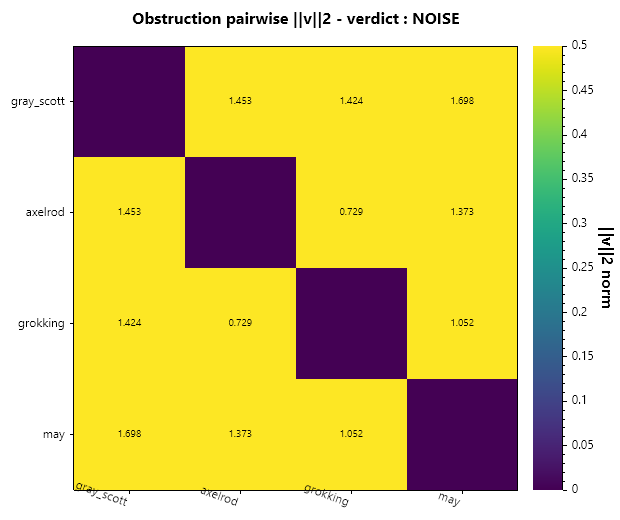


warning CS1701: Assuming assembly reference 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' used by 'Microsoft.DotNet.Interactive' matches identity 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' of 'Microsoft.AspNetCore.Html.Abstractions', you may need to supply runtime policy



In [9]:
// --- Visualisation : heatmap des pairwise norms ---
int n = noms.Count;
var M = new double[n, n];
int k = 0;
for (int i = 0; i < n; i++)
    for (int j = i + 1; j < n; j++)
    {
        M[i, j] = verdict.pairwise_norms[k];
        M[j, i] = M[i, j];
        k++;
    }

// Heatmap native de ScottPlot, l'equivalent d'imshow : rampe viridis, echelle
// bornee comme la source (vmin = 0, vmax = le seuil), ligne 0 en haut comme
// imshow (origin="upper"). La barre de couleurs est celle du plottable : sans
// elle, une teinte ne se lit pas.
var plt = new ScottPlot.Plot();
double vmax = Math.Max(verdict.noise_threshold, 0.5); // meme borne que la source
var heatmap = plt.Add.Heatmap(M);
heatmap.Colormap = new ScottPlot.Colormaps.Viridis();
heatmap.ManualRange = new ScottPlot.Range(0.0, vmax);
heatmap.FlipVertically = false; // ligne 0 en haut, comme la source
var palette = plt.Add.ColorBar(heatmap);
palette.Label = "||v||2 norm";

// Etiquettes des axes : le nom du substrat a chaque position d'indice. L'axe y
// de ScottPlot croit vers le haut alors que la ligne 0 est en haut : les noms y
// sont donc poses a l'envers pour que la ligne 0 se lise en premier.
double[] indices = Enumerable.Range(0, n).Select(x => (double)x).ToArray();
plt.Axes.Bottom.SetTicks(indices, noms.ToArray());
plt.Axes.Left.SetTicks(indices, noms.AsEnumerable().Reverse().ToArray());
plt.Axes.Bottom.TickLabelStyle.Rotation = 20;
plt.Axes.Bottom.TickLabelStyle.Alignment = ScottPlot.Alignment.UpperRight;

// Valeur de chaque case hors diagonale, noire ou blanche selon le fond.
for (int i = 0; i < n; i++)
    for (int j = 0; j < n; j++)
    {
        if (i == j) continue;
        var valeur = plt.Add.Text($"{M[i, j]:F3}", j, n - 1 - i);
        valeur.LabelFontSize = 10;
        valeur.LabelFontColor = M[i, j] < 0.3 ? Palette.Blanc : Palette.Noir;
        valeur.Alignment = ScottPlot.Alignment.MiddleCenter;
    }

plt.Title($"Obstruction pairwise ||v||2 - verdict : {verdict.verdict}");
plt.Grid.IsVisible = false;
plt.Axes.SetLimits(-0.5, n - 0.5, -0.5, n - 0.5);

display(HTML(plt.GetPngHtml(620, 520)));

## Lecture 5 -- La heatmap : un banc entier au-dessus de la palette

La heatmap donne à lire une conclusion que le tableau ne montre pas : la palette est bornée par `Math.Max(verdict.noise_threshold, 0.5)` (voir le code de la cellule), donc à `0.5` ici — et les 6 normes pairwise (de `0.7289` à `1.6985`) dépassent toutes la borne haute de la palette, fixée à 0.5 : chaque cellule hors diagonale rend la même couleur saturée, et la heatmap ne distingue plus aucune paire.

Pour discriminer, il faudrait une palette portée à la gamme réelle des normes (par exemple un `vmax` autour de `1.6985`, le max du banc) : les trois normes les plus élevées du banc sont celles des trois paires impliquant gray_scott, et elles tombent ici sur le même jaune saturé que les autres. C'est une direction d'amélioration de la visualisation — pas une correction du verdict : le verdict de la Lecture 4 ne dépend pas de la palette.

Le rendu suit la source pas à pas : `plt.Add.Heatmap` joue le rôle d'`imshow` avec son orientation par défaut (ligne 0 en haut), `ManualRange` celui du couple `vmin` / `vmax` (0 à `0.5`), les noms de substrats sont les étiquettes des graduations (`SetTicks`, inclinées à 20° sous l'axe, et posées à l'envers sur l'axe gauche puisque l'axe y croît vers le haut), et la barre de couleurs est attachée au plottable (`Add.ColorBar`, étiquetée `||v||2 norm`). La valeur de chaque case hors diagonale est posée en son centre.

### Exercice 2 — Sensibilité du verdict aux seuils `stable` / `noise`

Le verdict est une décision à deux seuils : `STABLE` si `mean_norm_l2 <= stable_threshold` (défaut 0.05), `NOISE` si `mean_norm_l2 >= noise_threshold` (défaut 0.30), `INCONCLUSIVE` entre les deux. La valeur committée `verdict.mean_norm_l2` est fixée par les quatre substrats — mais la *classification* dépend du choix des seuils.

**Objectif.** Pour le `mean_norm_l2` observé, déterminer la plage de `stable_threshold` qui ferait basculer le verdict vers `STABLE`, et la plage de `noise_threshold` qui le ferait basculer vers `NOISE`. Cela caractérise la *robustesse* de la conclusion : un verdict qui change pour un seuil à ±0.01 est fragile ; un verdict invariant sur [0.01, 0.20] est solide.

**Indices.**
- Le verdict se calcule par `MetaProxy.CrossSubstratObstruction(substrats, stableThreshold: s, noiseThreshold: n)` — les seuils sont des arguments nommés.
- Balayez par ex. `stableThreshold` sur `Stats.Linspace(0.01, 0.50, 25)` avec `noiseThreshold` fixé haut (0.99) pour isoler le basculement STABLE.
- Notez le plus petit `stableThreshold` pour lequel le verdict vaut `"STABLE"`.

In [10]:
// Exercice 2 — Robustesse du verdict au choix des seuils.
double mean_norm_committed = verdict.mean_norm_l2; // observable fixee par les 3 substrats
Console.WriteLine($"mean_norm_l2 committe = {mean_norm_committed:F4}");

// TODO etudiant : balayer stableThreshold (noiseThreshold fixe a 0.99 pour
// isoler le basculement vers STABLE) et identifier le seuil critique.
// MetaProxy.CrossSubstratObstruction(substrats, stableThreshold: s, noiseThreshold: 0.99)
double? bascule_stable = null; // plus petit stableThreshold donnant verdict == "STABLE"

// TODO etudiant (extension) : balayer noiseThreshold (stable fixe a 0.0)
// pour le basculement vers NOISE.
double? bascule_noise = null;

Console.WriteLine("Exercice 2 a completer — seuils de basculement attendus ici.");

mean_norm_l2 committe = 1.2882


Exercice 2 a completer — seuils de basculement attendus ici.


### Exercice 3 — Vérifier l'insensibilité à l'échelle de `ObstructionVector`

La normalisation par `|sig_a[k]| + |sig_b[k]|` rend le vecteur **insensible à l'échelle globale** : deux substrats dont les proxys diffèrent d'un facteur 10 doivent donner le même vecteur d'obstruction qu'à l'échelle 1. C'est une propriété falsifiable — vérifions-la.

**Objectif.** (a) Construire `sig_gs_x10` = `sig_gs` avec chaque proxy multiplié par 10. (b) Vérifier que `MetaProxy.ObstructionVector(sig_gs, sig_gs_x10)` est quasi nul (deux signatures *proportionnelles* → obstruction nulle). (c) Vérifier que `MetaProxy.ObstructionVector(sig_gs, sig_ax)` ≈ `MetaProxy.ObstructionVector(sig_gs_x10, sig_ax)` (le vecteur cross-substrat est inchangé par la remise à l'échelle d'un seul côté).

**Indices.**
- `Signature` est une classe à champs publics : construisez `sig_gs_x10` par `new Signature { spectral_gap = sig_gs.spectral_gap * 10, ... }`.
- `ObstructionVector(a, b)` renvoie un tuple dont le membre `normL2` résume l'amplitude ; comparez les `normL2`.

In [11]:
// Exercice 3 — Scale-invariance du vecteur d'obstruction (propriete falsifiable).
// TODO etudiant : construire sig_gs_x10 (chaque proxy multiplie par 10).
Signature sig_gs_x10 = null;

// TODO etudiant : (b) obstruction entre sig_gs et sa version x10 — attendu ~0.
(double spectral, double sensMean, double sensMax, double normL2)? vec_proportionnel = null;

// TODO etudiant : (c) comparer obstruction(sig_gs, sig_ax) vs obstruction(sig_gs_x10, sig_ax).
(double spectral, double sensMean, double sensMax, double normL2)? vec_echelle1 = null;
(double spectral, double sensMean, double sensMax, double normL2)? vec_echelle10 = null;

Console.WriteLine("Exercice 3 a completer — verification de l'insensibilite a l'echelle.");

Exercice 3 a completer — verification de l'insensibilite a l'echelle.


## Vérifiez votre compréhension

1. Le verdict cross-substrat est **NOISE** (`mean_norm_l2 = 1.2882`, `max = 1.6985`, seuil `STABLE <= 0.05`). Pourquoi ce verdict négatif est-il quand même un livrable honnête de la phase zéro, et non un échec d'instrument ?
2. Le vecteur d'obstruction `(a - b) / (|a| + |b| + eps)` est invariant d'échelle et antisymétrique. Que gagnerait-on à le rendre *symétrique*, et pourquoi ce choix changerait-il la lecture du désaccord entre proxys ?
3. L'exercice 2 fait varier les seuils `STABLE = 0.05` / `NOISE = 0.30` : le verdict NOISE peut-il basculer vers une autre classe sans changer les proxys ? Qu'est-ce que cela dit de la frontière entre calibration et résultat ?

## Écart assumé avec la source Python

Ce carnet est un **port**, pas une copie d'exécution. Deux organes n'ont pas d'équivalent direct sur la bibliothèque standard .NET et sont remplacés par un équivalent déclaré :

| Organe numpy | Remplacement C# | Effet mesuré |
|---|---|---|
| `np.random.default_rng` (PCG64) | `Rng64` (xorshift64\*, Box-Muller pour le normal) | Déterministe par graine, mais **flux différent** : Axelrod, Grokking et May donnent d'autres tirages. Gray-Scott est insensible (attracteur absorbant). |
| `np.linalg.eigvalsh` (LAPACK) | `Spectral.SymmetricEigenvalues` (Jacobi cyclique) | Accord à la précision machine sur les matrices 2×2 à 16×16 du banc ; les écarts résiduels sont documentés dans `known_differences`. |

Les grandeurs **déterministes** (Gray-Scott, seuils, structure du verdict) doivent coïncider avec la source ; les grandeurs **stochastiques** sont comparées à tolérance de Monte-Carlo. La paire est enregistrée dans `scripts/notebook_tools/twin_pairs.d/ict-15c-metaproxyobstruction.yaml` avec son attestation.

## À retenir

**Substrats testés** : Gray-Scott (V binarisée sur grille 64×64 intégrée 800 pas), Axelrod (stabilité de la stratégie dominante, alphabet binaire), Grokking (marche aléatoire biaisée, compression crossover à mi-parcours), May (biomasse du modèle de pâturage bistable discrétisée en 16 quantiles, régime sous le pli).

**Proxys calculés** : `spectral_gap` (gap spectral du Laplacien du graphe de transition), `sensitivity_mean` et `sensitivity_max` (sur **fonction identité `f(x) = x`** — l'observable dérivée du substrat, pas une fonction-test bivalente). Avec `f(x) = x%2` (livraison #7578), l'instrument saturait à `mean=max=1.0` sur alphabet binaire et `mean=max=2.0` sur alphabet quaternaire : la discrimination cross-substrat était artefactuelle. L'identité restaure un panel de valeurs non-plafonné.

**Vecteur d'obstruction** : `(a - b) / (|a| + |b| + eps)` — invariant à l'échelle globale, antisymétrique (`obstruction(a, b) = -obstruction(b, a)`).

**Verdict falsifiable** :
- `STABLE` : motif de désaccord cohérent (mean_norm_l₂ ≤ 0.05) sur ≥ 2 substrats — preuve empirique de l'objet.
- `NOISE` : motif aléatoire (mean_norm_l₂ ≥ 0.30) — verdict négatif honnête, la jambe meurt proprement.
- `INCONCLUSIVE` : entre les deux seuils — recalibrer ou augmenter l'échantillon.

**Portage C#** : six organes réécrits sur la BCL (`System`, `System.Linq`), aucun package numérique. Le Laplacien garde l'ordre d'association de la source (bit-exactitude du stencil), la matrice de transition garde son epsilon de lissage et son traitement silencieux des paires hors bornes, la sensibilité garde le correctif #9764 (voisinage lu sur les transitions *observées*, pas sur le graphe lissé).

## Suite logique (issue #7395)

Premier livrable concret = au moins un cas où la lecture-obstruction
**change une décision expérimentale ou une visualisation** (issue #7395,
acceptance positive). Si le verdict est `STABLE` ici : à documenter ; si
`NOISE` : à documenter aussi (verdict honnête). Si `INCONCLUSIVE` : à
recalibrer les seuils ou augmenter la taille d'échantillon.

## Discipline de nommage (HARD)

L'objet n'est **pas encore nommé**. Le vocabulaire utilisé reste
descriptif (`obstruction vector`, `pairwise norm`, `STABLE / NOISE`).
Aucune lettre grecque décorée sur un objet non encore constaté — la
stabilisation empirique précède le baptême.

## Pour aller plus loin

- La source Python de ce carnet : [ICT-15c — Méta-proxy d'obstruction (Python)](ICT-15c-MetaProxyObstruction-Python.ipynb).
- La phase un applique une cochaîne de Čech aux mêmes substrats : [ICT-15d — Obstruction Čech](ICT-15d-CechObstruction-Python.ipynb).
- L'exploitation de la conjecture de Huang sur les mêmes bancs réels : [ICT-15g](ICT-15g-EmpiricalHuangExploitation-Python.ipynb).
- La leçon d'observable (identité vs binarisme plafonné, livraison #7578) se rejoue dans [ICT-15j — nerf discriminant](ICT-15j-NerveDiscriminant-Python.ipynb).
- Revenir au [cadrage de la série](../ICT-0-Framing.md).